# Are the OPFData predictors uniformly distributed?

The effective-centre Hessian reconstruction (`weeks/2026-W45/tree_hessian`) assumes the rows fill every tree box
**evenly**. This notebook measures how far the observed data are from that assumption: first over the whole dataset,
then inside the boxes of an actual fitted CART tree. Data: `118_ieee_smol.csv`, columns 1–3 (Load 1–3), 5,000 rows.
Run from this folder.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.tree import DecisionTreeRegressor
from pathlib import Path
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parents[2] / "2026-W45"))
from tree_hessian.tree_extract import extract_nodes

CSV = next(p for p in [Path("/Users/tonys/Desktop/Class/Decision Trees/datasets/118_ieee_smol.csv"),
                       Path("118_ieee_smol.csv"), Path("/mnt/user-data/uploads/118_ieee_smol.csv")] if p.is_file())
df = pd.read_csv(CSV, header=None, usecols=range(4)).to_numpy(float)
y, X = df[:, 0], df[:, 1:]
names = ["Load 1", "Load 2", "Load 3"]



## 1. Whole dataset
Kolmogorov–Smirnov test of each load against a uniform distribution on its own [min, max]; variance and central-half
fraction of the rescaled load (uniform: 0.0833 and 0.50); pairwise correlations (independent uniform: 0).

In [2]:
# ---------- 1. global marginals ----------
print("=== 1. Global marginals: KS test against Uniform[min,max] ===")
for k in range(3):
    lo, hi = X[:, k].min(), X[:, k].max()
    D, p = stats.kstest(X[:, k], "uniform", args=(lo, hi - lo))
    u = (X[:, k] - lo) / (hi - lo)
    print(f"{names[k]}: KS D={D:.3f} p={p:.1e} | mean of scaled={u.mean():.3f} (uniform 0.5) var={u.var():.4f} (uniform 0.0833) "
          f"| frac in central half={((u>0.25)&(u<0.75)).mean():.3f} (uniform 0.50)")
print("pairwise correlations (independent uniform => 0):")
print(np.corrcoef(X.T).round(3))
# product-of-uniforms structure
m = X.mean(0); R = X / m
print(f"row-wise std of (load/mean) across the 3 loads = {R.std(1).mean():.3f}; std of row-mean factor = {R.mean(1).std():.3f}")



=== 1. Global marginals: KS test against Uniform[min,max] ===
Load 1: KS D=0.175 p=4.4e-135 | mean of scaled=0.448 (uniform 0.5) var=0.0425 (uniform 0.0833) | frac in central half=0.729 (uniform 0.50)
Load 2: KS D=0.172 p=1.1e-129 | mean of scaled=0.448 (uniform 0.5) var=0.0424 (uniform 0.0833) | frac in central half=0.729 (uniform 0.50)
Load 3: KS D=0.162 p=1.3e-115 | mean of scaled=0.451 (uniform 0.5) var=0.0451 (uniform 0.0833) | frac in central half=0.709 (uniform 0.50)
pairwise correlations (independent uniform => 0):
[[1.    0.473 0.487]
 [0.473 1.    0.491]
 [0.487 0.491 1.   ]]
row-wise std of (load/mean) across the 3 loads = 0.087; std of row-mean factor = 0.132


## 2. Inside the fitted boxes
For every internal node of a depth-7, leaf≥50 tree (2D and 3D): the fraction of rows left of the split versus the
geometric fraction `(tau − lo) / (hi − lo)`; a per-axis KS test of the rows' positions in the box; and the centroid
offset from the box centre as a fraction of the box width. Uniform fill gives 0 gap, p ≈ uniform, 0 offset.

In [3]:
# ---------- 2. within-box fill, setting B tree ----------
print("\n=== 2. Inside fitted CART boxes (depth 7, min_samples_leaf 50), D=2 and D=3 ===")
rows = []
for D in (2, 3):
    XD = X[:, :D]
    t = DecisionTreeRegressor(max_depth=7, min_samples_leaf=50, random_state=0).fit(XD, y)
    nodes = extract_nodes(t, XD.min(0), XD.max(0))
    for n in nodes.values():
        if n.is_leaf: continue
        mask = np.all((XD >= n.lo) & (XD <= n.hi), axis=1); P = XD[mask]
        s = n.feature
        geom_left = (n.threshold - n.lo[s]) / (n.hi[s] - n.lo[s])      # volume fraction left of tau
        emp_left  = (P[:, s] <= n.threshold).mean()                      # row fraction left of tau
        ks = [stats.kstest((P[:, k]-n.lo[k])/(n.hi[k]-n.lo[k]), "uniform").pvalue for k in range(D)]
        off = np.abs(P.mean(0) - (n.lo+n.hi)/2) / (n.hi-n.lo)
        rows.append(dict(D=D, node=n.id, depth=n.depth, n=int(mask.sum()), axis=s+1,
                         geom_left=geom_left, emp_left=emp_left, left_gap=emp_left-geom_left,
                         min_KS_p=min(ks), max_centroid_offset=off.max()))
T = pd.DataFrame(rows)
for D in (2, 3):
    t_ = T[T.D == D]
    print(f"D={D}: {len(t_)} internal nodes | nodes with KS p<0.05 on some axis: {(t_.min_KS_p<0.05).mean():.0%} "
          f"| |row-fraction-left − volume-fraction-left|: mean {t_.left_gap.abs().mean():.3f}, max {t_.left_gap.abs().max():.3f} "
          f"| centroid offset/width: mean {t_.max_centroid_offset.mean():.3f}, max {t_.max_centroid_offset.max():.3f}")
    print("  by depth (mean |left gap|):", t_.groupby("depth").left_gap.apply(lambda v: v.abs().mean()).round(3).to_dict())
T.to_csv("within_box_uniformity.csv", index=False)




=== 2. Inside fitted CART boxes (depth 7, min_samples_leaf 50), D=2 and D=3 ===


D=2: 59 internal nodes | nodes with KS p<0.05 on some axis: 71% | |row-fraction-left − volume-fraction-left|: mean 0.132, max 0.389 | centroid offset/width: mean 0.109, max 0.333
  by depth (mean |left gap|): {0: 0.05, 1: 0.213, 2: 0.262, 3: 0.266, 4: 0.165, 5: 0.076, 6: 0.043}
D=3: 46 internal nodes | nodes with KS p<0.05 on some axis: 96% | |row-fraction-left − volume-fraction-left|: mean 0.206, max 0.461 | centroid offset/width: mean 0.155, max 0.326
  by depth (mean |left gap|): {0: 0.087, 1: 0.224, 2: 0.317, 3: 0.313, 4: 0.189, 5: 0.192, 6: 0.118}


## 3. Figures
Left: observed rows with the fitted leaf boxes. Middle/right: per-load histograms against the uniform density.
Second figure: one point per internal node; uniform fill would place every node on the diagonal.

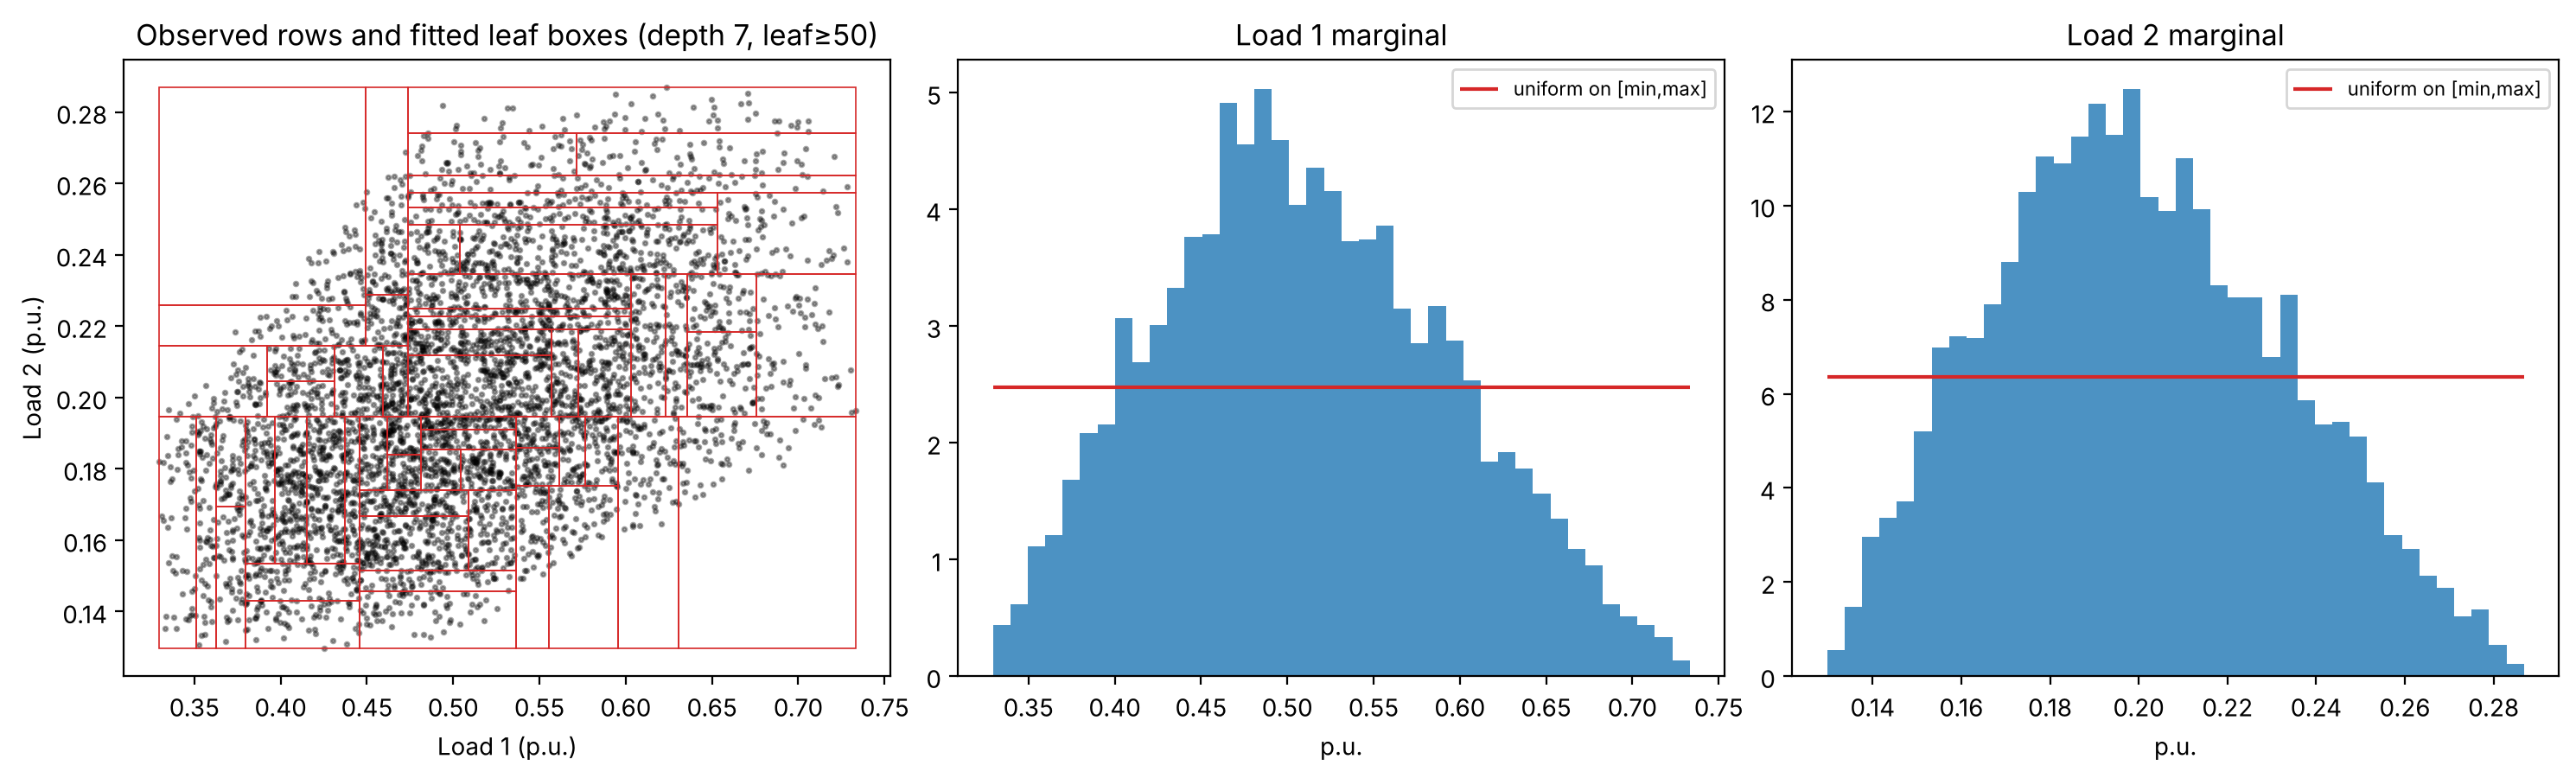

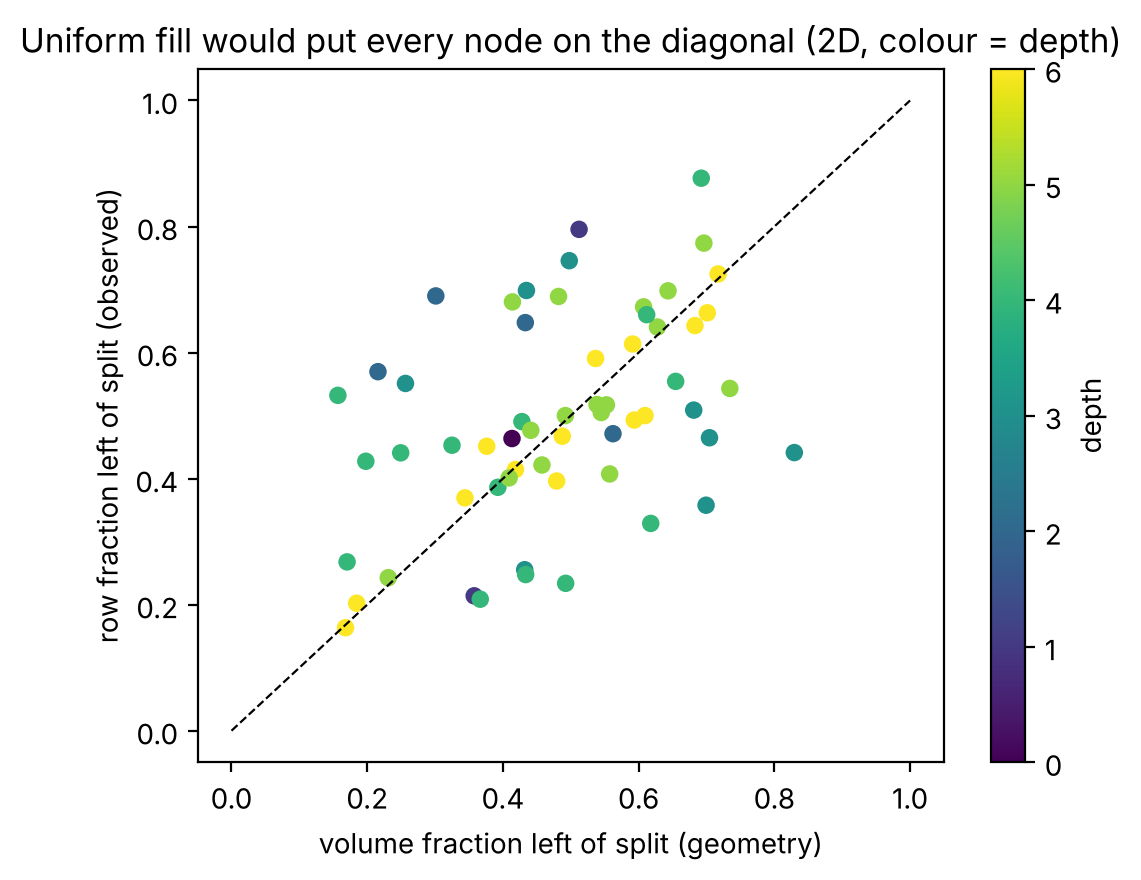

In [4]:
# ---------- 3. figure: 2D scatter with boxes + marginal histograms ----------
X2 = X[:, :2]
t = DecisionTreeRegressor(max_depth=7, min_samples_leaf=50, random_state=0).fit(X2, y)
nodes = extract_nodes(t, X2.min(0), X2.max(0))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].scatter(X2[:, 0], X2[:, 1], s=3, alpha=.35, c="k")
for n in nodes.values():
    if n.is_leaf:
        ax[0].add_patch(plt.Rectangle((n.lo[0], n.lo[1]), n.hi[0]-n.lo[0], n.hi[1]-n.lo[1], fill=False, ec="tab:red", lw=.6))
ax[0].set(xlabel="Load 1 (p.u.)", ylabel="Load 2 (p.u.)", title="Observed rows and fitted leaf boxes (depth 7, leaf≥50)")
for k, a in zip(range(3), ax[1:]):
    a.hist(X[:, k], bins=40, color="tab:blue", alpha=.8, density=True)
    lo, hi = X[:, k].min(), X[:, k].max(); a.hlines(1/(hi-lo), lo, hi, colors="tab:red", label="uniform on [min,max]")
    a.set(title=f"{names[k]} marginal", xlabel="p.u."); a.legend(fontsize=8)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
t2 = T[T.D == 2]
ax.scatter(t2.geom_left, t2.emp_left, c=t2.depth, cmap="viridis", s=28); ax.plot([0,1],[0,1],"k--",lw=.8)
ax.set(xlabel="volume fraction left of split (geometry)", ylabel="row fraction left of split (observed)",
       title="Uniform fill would put every node on the diagonal (2D, colour = depth)")
fig.colorbar(ax.collections[0], label="depth"); fig.tight_layout(); plt.show()


## Reading
The loads are bell-shaped and correlated, not uniform. Inside the boxes the observed left fraction misses the
geometric one by 0.13 (2D) to 0.21 (3D) on average and up to 0.46, worst at depths 1–3. The uniform-fill assumption
behind the `(lo + tau + hi)/3` location is therefore violated on this data, most strongly at the depths that supply
most pairs to the curvature system. This notebook does not change the method; the follow-up that replaces the
assumed location with the measured one belongs to its own documented experiment.